# 四道可以改数的生成模型练习

从头运行一次。第一格准备绘图工具，后面四题可以单独改参数重跑。笔记本内含全部代码和默认结果，计算与绘图只用 Python 标准库。

### 准备绘图工具

先运行下一格。它负责把数字画出来，四道题的计算都写在各题下面。

In [1]:
import base64, struct, zlib
from html import escape
from math import sqrt, tanh
from random import Random

GRID, INK, MUTED, RUST, TEAL, WIDTH = '#c8d7d0', '#193540', '#495f66', '#ad492c', '#00695f', 660

def square(frame, row):
    """六帧小片里的一张灰度图，方块每帧向右移一列。"""
    center = 4 + frame
    return [[0.8 if abs(x-center)<=1 and abs(y-row)<=1 else -0.55
             for x in range(16)] for y in range(12)]

class Picture:
    def __init__(self, markup):
        self.markup = markup

    def _repr_svg_(self):
        return self.markup

    def __repr__(self):
        return "实验输出图"

def text(left, top, content, size=15, color=INK, anchor="start", bold=False):
    return (f'<text x="{left}" y="{top}" font-size="{size}" fill="{color}" text-anchor="{anchor}" '
            f'font-weight="{700 if bold else 400}">{escape(str(content))}</text>')

def line(left, top, right, bottom, color=GRID, width=1, dash=""):
    return (f'<line x1="{left}" y1="{top}" x2="{right}" y2="{bottom}" stroke="{color}" '
            f'stroke-width="{width}" stroke-dasharray="{dash or "none"}"/>')

def rect(left, top, width, height, fill, radius=0):
    return f'<rect x="{left}" y="{top}" width="{width}" height="{height}" rx="{radius}" fill="{fill}"/>'

def circle(left, top, radius, color):
    return f'<circle cx="{left}" cy="{top}" r="{radius}" fill="{color}"/>'

def svg(title, height, pieces):
    return (f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {WIDTH} {height}" role="img" '
            f'aria-label="{escape(title)}" font-family="MiSans, Noto Sans CJK SC, Microsoft YaHei, sans-serif">'
            f'<title>{escape(title)}</title>' + rect(0, 0, WIDTH, height, "#fbfcf8")
            + "".join(pieces) + '</svg>')

def png_uri(rows):
    def block(name, payload):
        return struct.pack(">I", len(payload)) + name + payload + struct.pack(">I", zlib.crc32(name+payload))
    header = struct.pack(">IIBBBBB", len(rows[0]), len(rows), 8, 0, 0, 0, 0)
    stream = b"".join(b"\x00"+bytes(row) for row in rows)
    png = b"\x89PNG\r\n\x1a\n"+block(b"IHDR", header)+block(b"IDAT", zlib.compress(stream))+block(b"IEND", b"")
    return "data:image/png;base64,"+base64.b64encode(png).decode()

def bitmap(rows, left, top, width):
    return (f'<image x="{left}" y="{top}" width="{width}" height="{width*len(rows)/len(rows[0])}" '
            f'style="image-rendering:pixelated" href="{png_uri(rows)}"/>')

def gray(values):
    return [[round((max(-1,min(1,v))+1)*127.5) for v in row] for row in values]

def noise_plot(result):
    parts = []
    for i,(pixels,label) in enumerate(zip(result,("干净的帧 2","混入雪花","按猜测还原"))):
        left = 24+216*i
        parts.extend([text(left,24,label,16,TEAL,bold=True),bitmap(gray(pixels),left,35,160),
                      text(left,180,f"框内 {pixels[3][6]:.4f}",15,INK)])
        parts.append(f'<rect x="{left+60}" y="65" width="10" height="10" fill="none" stroke="#ffad46" stroke-width="2"/>')
    return svg("同一格亮度在加噪和还原后怎样变化",190,parts)

def flow_plot(steps,start):
    parts = []
    extent = max(1.6,abs(start)*1.1)
    for i,n in enumerate((1,steps)):
        left = 45+321*i
        px = lambda k: left+247*k/n
        py = lambda value: 132-78*value/extent
        parts.append(text(left,23,f"问 {n} 次速度",17,TEAL,bold=True))
        for y in (-1,0,1):
            parts.extend([line(left,py(y),px(n),py(y),"#ccd9d2",1,"4 3"),
                          text(left-8,py(y)+5,str(y),13,MUTED,"end")])
        for z in (-1.4,-.8,-.4,.4,.8,1.4,start):
            track = lane_path(z,n)
            color = RUST if z==start else TEAL
            points = " ".join(f"{px(k):.3f},{py(x):.3f}" for k,x in enumerate(track))
            parts.extend([f'<polyline fill="none" points="{points}" stroke="{color}" stroke-width="{2.7 if z==start else 1.4}"/>',
                          circle(px(n),py(track[-1]),3.5,color)])
        parts.extend([text(left,230,"噪声端 0",13,MUTED),text(px(n),230,"成片端 1",13,MUTED,"end"),
                      text(left,257,f"起点 {start:g}　→　{lane_path(start,n)[-1]:.4f}",15,RUST,bold=True)])
    return svg("同一批纵坐标分别用一步和多步沿平均速度向两条目标行生成",270,parts)

def video_plot(result):
    independent,shared,legal,possible = result
    parts = []
    for i,(rows,label) in enumerate(((independent,"每帧各抽"),(shared,"整段共用"))):
        top = 34+76*i
        parts.append(text(10,top+25,label,15,TEAL,bold=True))
        for f,row in enumerate(rows):
            left = 117+88*f
            parts.extend([bitmap(gray(square(f,row)),left,top,69),
                          text(left+34,top+67,f"行 {row}",13,INK,"middle")])
    parts.append(text(12,200,f"独立抽行共有 {possible} 种结果，只有 {legal} 种全程保持同一行。",15,INK))
    return svg("六帧方块的逐帧抽行和整段共用行号",212,parts)

def control_plot(result):
    history,positions = result
    parts = [text(18,24,"出口权重 w 从零开始学习",16,TEAL,bold=True),
             text(345,24,"用同一权重，分别要求上下两行",16,TEAL,bold=True)]
    px = lambda k: 48+240*k/max(1,len(history)-1)
    py = lambda w: 151-93*w
    for w in (0,1):
        parts.extend([line(48,py(w),288,py(w),"#c5d6ce",1,"5 3"),text(38,py(w)+4,str(w),13,MUTED,"end")])
    points = " ".join(f"{px(k):.3f},{py(w):.3f}" for k,w in enumerate(history))
    parts.extend([f'<polyline points="{points}" fill="none" stroke="{TEAL}" stroke-width="2"/>',
                  circle(px(len(history)-1),py(history[-1]),4,TEAL),
                  text(18,181,f"{len(history)-1} 次更新后 w = {history[-1]:.4f}",15,INK)])
    lo,hi=min(2,*positions),max(8,*positions)
    screen_y = lambda row: 47+99*(row-lo)/(hi-lo)
    for i,(target,actual) in enumerate(zip((3,7),positions)):
        left=350+149*i
        parts.extend([rect(left,43,121,109,"#e8efe9",3),line(left,screen_y(target),left+121,screen_y(target),RUST,1.8,"5 3"),
                      circle(left+58,screen_y(actual),6,TEAL),text(left,179,f"预测行 {actual:.3f}",14,INK)])
    parts.append(text(18,206,"虚线是请求的行，青点是冻结主干加上位置修正后的连续坐标。",14,MUTED))
    return svg("标量控制支路的学习曲线与两种请求的实际响应",218,parts)

## 扩散 · 雪花猜多一点，亮块会变暗多少？

讲义第 2、7–8 页。只看六帧方块中的帧 2。干净图 y 混入标准高斯噪声 z，得到 x = a·y + σ·z。取 a = 0.8、σ = 0.6。我们知道出题用的 z，故意把它猜为 z + δ，再按 ŷ = (x − σ·猜测)/a 还原。每格的偏差都是 −σδ/a。

先猜 δ 改成 0 后橙框会读到什么。再试 −0.15，检查橙框会变亮还是变暗。这里用已知噪声做校验，训练去噪网络的流程见第 29 页。

[DDPM 论文](https://arxiv.org/abs/2006.11239)

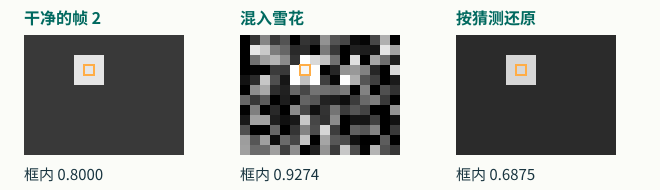

In [2]:
def noise_problem(noise_error):
    original = square(frame=2, row=3)
    rng = Random(17)
    noise = [[rng.gauss(0,1) for x in range(16)] for y in range(12)]
    a = 0.8
    sigma = sqrt(1-a*a)
    mixed = [[a*y + sigma*z for y,z in zip(pixels,snow)]
             for pixels,snow in zip(original,noise)]
    # 已知这次出题用的噪声，给每一格的猜测故意加同样的误差。
    restored = [[(x-sigma*(z+noise_error))/a for x,z in zip(pixels,snow)]
                for pixels,snow in zip(mixed,noise)]
    return original, mixed, restored

noise_error = 0.15
Picture(noise_plot(noise_problem(noise_error)))

## 流匹配 · 一份噪声会停在中间，还是走向一条车道？

讲义第 3、10–11、89 页。把两条目标行写成 y = −1 或 +1，各占一半。起点 z 是独立的标准高斯数，练习路径为 x = (1−t)z + ty。在同一题面，平均终点是 tanh(tx/(1−t)²)，平均速度是 (平均终点−x)/(1−t)。这组分布允许用公式精确计算速度，省去了拟合网络的误差。

先把 steps 改为 2，再改为 12，盯着橙线的终点。把 start 改为 0，找出对称中心为什么会一直停住。图中的起点是特意选来观察轨迹的几个数。

[Flow Matching 论文](https://arxiv.org/abs/2210.02747)

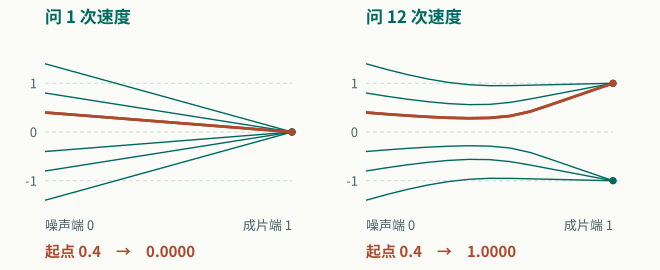

In [3]:
def lane_speed(x, t):
    # y 取 -1 或 +1，各占一半；z 是独立标准高斯噪声。
    mean_y = tanh(t*x/(1-t)**2)
    return (mean_y-x)/(1-t)

def lane_path(z, steps):
    if steps < 1:
        raise ValueError("至少走一步")
    path = [z]
    for k in range(steps):
        t = k/steps
        x = path[-1]
        path.append(x + lane_speed(x,t)/steps)
    return path

steps = 12
start = 0.4
Picture(flow_plot(steps, start))

## 视频 · 每一帧都在合法行，连起来有多少段会跳？

讲义第 4、13–14 页。数据里每段方块向右走，整段任选第 3 或第 7 行。逐帧独立抽签和整段共用一次抽签，每一帧落在任一行的概率都是 ½。六次独立抽签会产生 2⁶ 条等概率序列，其中全上、全下两条符合整段规则。

改 seed 可以换一卷。两排的首帧相同，横着读第二至六帧。独立抽签整段合法的概率为 2/64。这个抽签实验隔离了帧间依赖，第 14 页再看实际联合去噪。

[Video Diffusion Models 论文](https://arxiv.org/abs/2204.03458)

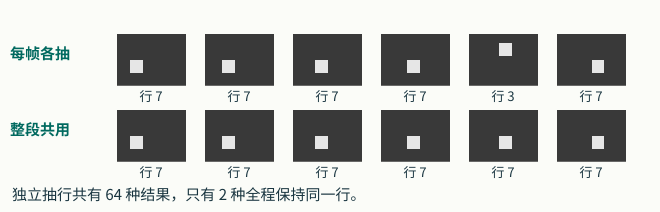

In [4]:
def video_lanes(seed):
    rng = Random(seed)
    rows = [rng.choice((3,7)) for frame in range(6)]
    # 共享首帧的抽签结果，其余帧保持同一行。
    shared = [rows[0]]*6
    legal = 2                      # 全在第 3 行，或全在第 7 行
    possible = 2**len(rows)         # 每一帧独立二选一
    return rows, shared, legal, possible

seed = 17
Picture(video_plot(video_lanes(seed)))

## ControlNet · 出口起初是零，两个位置提示何时能分开？

讲义第 5、16、85–87 页。主干 h 冻结在 0，条件 c 取 −1、+1，两个目标分别是 c 本身。出口只有一个参数 w，从 0 开始学。训练用强度 1，最小化 ½·平均[(wc−c)²]，所以梯度等于 w−1。生成时才用 h + λwc 读数，乘 2 再加 5 就是屏幕行号。

先设 updates = 0，试着改变强度。然后恢复 8 次更新，再把 strength 设成 0。两者都能让位置回到第 5 行，权重曲线却不同。此处的单参数回归演示控制出口，视频网络的多尺度出口见第 86 页。

[ControlNet 论文](https://arxiv.org/abs/2302.05543)

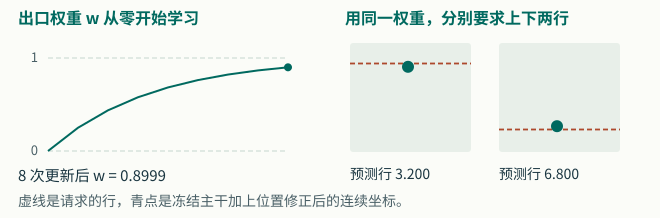

In [5]:
def train_exit(updates, strength):
    if updates < 0:
        raise ValueError("训练次数不能为负")
    weight = 0.0
    history = [weight]
    for step in range(updates):
        # 冻结主干 h=0。训练用强度 1，两个条件同样常见，目标值就是条件 c。
        gradient = sum((weight*c-c)*c for c in (-1,1))/2
        weight -= 0.25*gradient
        history.append(weight)
    # 归一化坐标 -1、+1 分别对应第 3、7 行。
    return history, [5+2*strength*weight*c for c in (-1,1)]

updates = 8
strength = 1
Picture(control_plot(train_exit(updates, strength)))